this notebook aims to generate the VLE of acetone-water

In [1]:
# imports to enable the notebook to access the src folder
import sys
import os
sys.path.append(os.path.dirname(os.getcwd()))

# import the necessary packages
from src.molecules import StructuralValidator
from src.pure import PropertyCalculator
from src.pure import AntoineCalculator
from src.data import load_unifac_data
from src.mixture.unifac.pyomo_vle import pyo_vle
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# step1: define the compounds
mixture = {'acetone': {'CH3':1, 'CH3CO':1},
           'water': {'H2O':1},
           #'DOH': {'DOH':1}
           }
# validate the structures
validator = StructuralValidator()
validator.validate(mixture)

{'acetone': True, 'water': True}

In [3]:
# step2: calculate the required properties
prop_list = ['tc', 'pc', 'tb', 'ac', 'hv']
pure_calc = PropertyCalculator()
pure_props = pure_calc.calculate(mixture, prop_list)
# fix the properties of acetone
pure_props['acetone']['tc'] = 508.1
pure_props['acetone']['pc'] = 48.0
pure_props['acetone']['tb'] = 329.3
print(pure_props)
# step3: calculate the Antoine coefficients
antoine_params = {}
antoine_calc = AntoineCalculator()
for compound, props in pure_props.items():
    results = antoine_calc.calculate_antoine_parameters(mixture, critical_properties=props, method='enthalpy_vap')
    print('optimization results was', results['termination_condition'] )
    antoine_params[compound] = {}
    antoine_params[compound]['A'] = results['A']
    antoine_params[compound]['B'] = results['B']
    antoine_params[compound]['C'] = results['C']



# step4: perform the vle
# define number of data points
n_data = 100
# set composition
x1 = np.linspace(0, 1, n_data)  # Component 1: 0 to 1
x2 = 1 - x1                     # Component 2: 1 to 0 (complement)
x = np.column_stack([x1, x2])  # Combine into 2D array
# provide nitial guess for temperature
# Extract boiling points
boiling_points = [props['tb'] for props in pure_props.values()]
T_min = min(boiling_points) 
T_max = max(boiling_points)  
T0 = np.linspace(T_min, T_max, n_data)
# Load all UNIFAC parameters
rk_data, qk_data, interaction_data = load_unifac_data()
# perform the VLE calculation
results, model = pyo_vle(x, T0, mixture, rk_data, qk_data, interaction_data, antoine_params, verbose=False)

gamma = np.empty_like(x)
T = np.empty_like(T0)
y = np.empty_like(x)
psat = np.empty_like(x)

for i in model.gamma.keys():
    gamma[i] = model.gamma[i].value
for i in model.T.keys():
    T[i] = model.T[i].value

for i in model.y.keys():
    y[i] = model.y[i].value

for i in model.psat.keys():
    psat[i] = model.psat[i].value

{'acetone': {'tc': 508.1, 'pc': 48.0, 'tb': 329.3, 'ac': 0.33226923286882887, 'hv': 29.944}, 'water': {'tc': 646.9999999999999, 'pc': 220.6400000000002, 'tb': 373.1499999999999, 'ac': 0.3448609999999985, 'hv': 43.9883}}
optimization results was optimal
optimization results was optimal


In [4]:
# perform azeotrope detection
from src.mixture.unifac.pyomo_azeo import pyo_azeo
T0_az = T_max#np.array((T_min+T_max)/2)
x0_az = np.array([[0.5, 0.5]])
results_az, model_az = pyo_azeo(x0_az, T0_az, mixture, rk_data, qk_data, interaction_data, antoine_params, verbose=False)
# retrieving the solutions
gamma_az = np.empty_like(x0_az)
T_az = np.empty_like(T0_az)
y_az = np.empty_like(x0_az)
x_az = np.empty_like(x0_az)
psat_az = np.empty_like(x0_az)


for i in model_az.gamma.keys():
    gamma_az[i] = model_az.gamma[i].value

for i in model_az.T.keys():
    T_az = model_az.T[i].value

for i in model_az.y.keys():
    y_az[i] = model_az.y[i].value

for i in model_az.x.keys():
    x_az[i] = model_az.x[i].value

for i in model_az.psat.keys():
    psat_az[i] = model_az.psat[i].value
print('Azeotrope found at T=', T_az, 'K')
print('Liquid composition:', x_az)
print('Vapor composition:', y_az)

Azeotrope found at T= 329.2483214386632 K
Liquid composition: [[0.97684131 0.02315869]]
Vapor composition: [[0.97684104 0.02315896]]


we make xy diagram

Figures saved as:
  - acetone_water_xy_diagram.pdf (use this for LaTeX)
  - acetone_water_xy_diagram.png (for presentations/web)


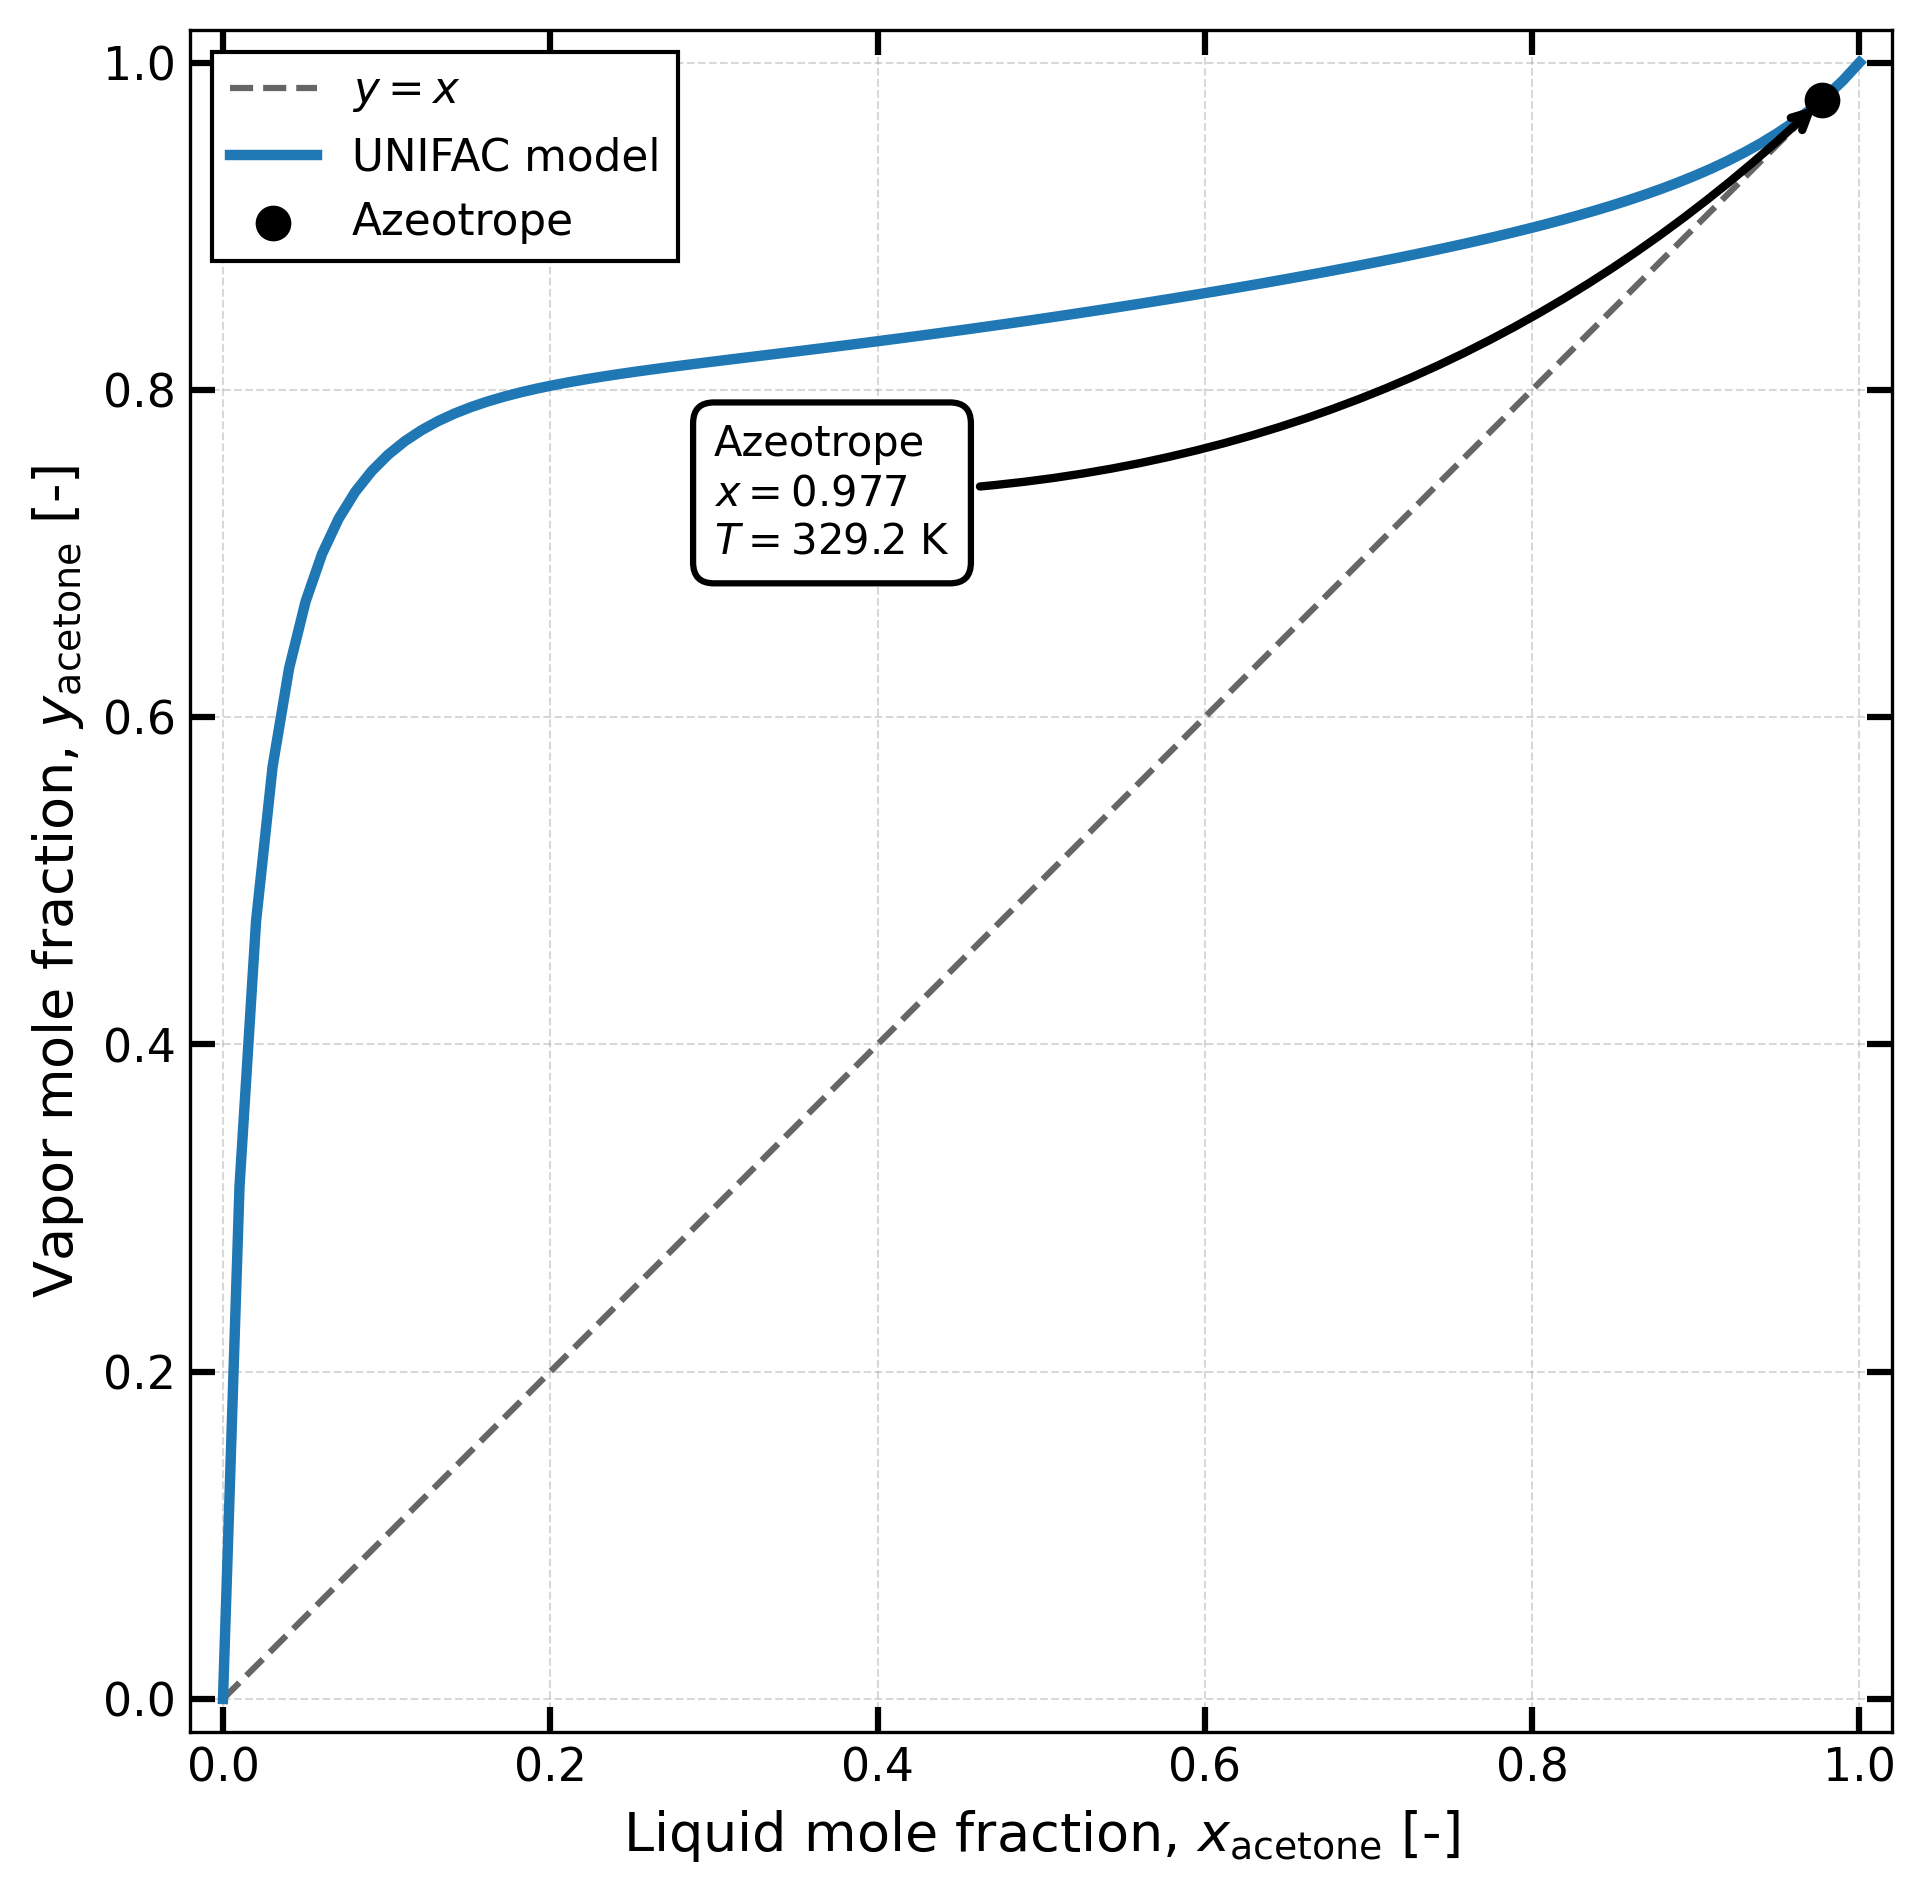

In [6]:
# Publication-quality x-y diagram with azeotrope
fig, ax = plt.subplots(figsize=(6.5, 6.5), dpi=300)

# Plot diagonal reference line first (in background)
ax.plot([0, 1], [0, 1], 'k--', linewidth=1.5, alpha=0.6, label='$y = x$', zorder=1)

# Plot VLE curve
ax.plot(x[:, 0], y[:, 0], color='#1f77b4', linewidth=2.5,
        label='UNIFAC model', zorder=3)

# Extract scalar values for azeotrope
x_az_val = float(x_az[0][0])
y_az_val = float(y_az[0][0])
T_az_val = float(T_az)

# Plot azeotrope point as small black circle
ax.scatter(x_az_val, y_az_val, s=50, marker='o', color='black',
           edgecolors='black', linewidths=1.5, label='Azeotrope', zorder=5)

# Add annotation for azeotrope (positioned inside plot)
ax.annotate(f'Azeotrope\n$x = {x_az_val:.3f}$\n$T = {T_az_val:.1f}$ K',
            xy=(x_az_val, y_az_val), xytext=(0.3, 0.7),
            fontsize=10, ha='left',
            bbox=dict(boxstyle='round,pad=0.5', facecolor='white', 
                     edgecolor='black', linewidth=1.5),
            arrowprops=dict(arrowstyle='->', connectionstyle='arc3,rad=0.2',
                          color='black', lw=2))

# Axis labels with proper formatting
ax.set_xlabel('Liquid mole fraction, $x_{\\mathrm{acetone}}$ [-]',
              fontsize=13, fontweight='normal')
ax.set_ylabel('Vapor mole fraction, $y_{\\mathrm{acetone}}$ [-]',
              fontsize=13, fontweight='normal')

# Set equal aspect ratio and limits
ax.set_aspect('equal')
ax.set_xlim(-0.02, 1.02)
ax.set_ylim(-0.02, 1.02)

# Improve tick labels
ax.tick_params(axis='both', which='major', labelsize=11, direction='in',
               length=6, width=1.5, top=True, right=True)

# Legend with better positioning
ax.legend(loc='upper left', fontsize=10.5, frameon=True, fancybox=False,
          edgecolor='black', framealpha=1)

# Subtle grid
ax.grid(True, linestyle='--', linewidth=0.5, alpha=0.3, color='gray')

# Tight layout for better spacing
plt.tight_layout()

# Save in multiple formats for different uses
# PDF for LaTeX (vector format, perfect quality at any scale)
plt.savefig('acetone_water_xy_diagram.pdf', dpi=300, bbox_inches='tight', 
            facecolor='white', edgecolor='none', format='pdf')
# PNG for presentations/web
plt.savefig('acetone_water_xy_diagram.png', dpi=300, bbox_inches='tight', 
            facecolor='white', edgecolor='none', format='png')

print("Figures saved as:")
print("  - acetone_water_xy_diagram.pdf (use this for LaTeX)")
print("  - acetone_water_xy_diagram.png (for presentations/web)")

plt.show()